# Анализ тональности отзывов Кинопоиска: EDA и классический baseline

В этом ноутбуке подготавливаем данные, исследуем распределение классов и длины отзывов, а затем обучаем воспроизводимый baseline на TF-IDF и логистической регрессии.

**Задача:** по тексту русскоязычного отзыва предсказать одну из трёх меток — `bad`, `neutral` или `good`.

Данные: [Kinopoisk Reviews на Kaggle](https://www.kaggle.com/datasets/halssara/kinopoisk-reviews). Дообучение RuBERT находится в ноутбуке `kinopoisk-bert.ipynb`.

## 1. Настройка и загрузка данных

Ноутбук можно запустить локально с CSV в каталоге `data/` или на Kaggle с подключённым датасетом. Все случайные операции фиксируются значением `SEED`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

SEED = 42
LABELS = ['bad', 'good', 'neutral']
DATA_CANDIDATES = [
    Path('/kaggle/input/kinopoisk-reviews/data.csv'),
    Path('/kaggle/input/kinopoisk-reviews/kinopoisk_reviews_clean.csv'),
    Path('data/data.csv'),
    Path('data/kinopoisk_reviews_clean.csv'),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place data.csv or kinopoisk_reviews_clean.csv in data/.')

raw_data = pl.read_csv(DATA_PATH)
print(f'Data: {DATA_PATH}')
print(f'Raw shape: {raw_data.shape}')
raw_data.head(3)

Data: data\data.csv
Raw shape: (33863, 3)


film_name,user_review,review_type
str,str,str
"""Unknown""","""О чём фильм?Оскар Шиндлер (Лиа…","""good"""
"""Unknown""","""«Список Шиндлера»- это америка…","""good"""
"""Unknown""","""Спилберг славится своим профес…","""good"""


## 2. Проверка и очистка

Удаляем пустые тексты и полные дубликаты. Колонка `film_name` удаляется только если она не содержит никакой информации, то есть целиком равна `Unknown`. Метки не перебалансируются: вместо этого используем веса классов в модели и отдельно смотрим macro F1.

In [2]:
required_columns = {'user_review', 'review_type'}
missing_columns = required_columns - set(raw_data.columns)
if missing_columns:
    raise ValueError(f'Missing columns: {sorted(missing_columns)}')

unexpected_labels = set(raw_data['review_type'].drop_nulls().unique()) - set(LABELS)
if unexpected_labels:
    raise ValueError(f'Unexpected labels: {sorted(unexpected_labels)}')

duplicate_rows = raw_data.height - raw_data.unique().height
data = raw_data.filter(
    pl.col('user_review').is_not_null()
    & pl.col('review_type').is_not_null()
    & (pl.col('user_review').str.strip_chars() != '')
).unique(keep='first', maintain_order=True)

if 'film_name' in data.columns:
    film_names = data['film_name'].unique().to_list()
    print(f'Film names: {film_names[:10]}')
    if film_names == ['Unknown']:
        data = data.drop('film_name')

conflicting_texts = (
    data.group_by('user_review')
    .agg(pl.col('review_type').n_unique().alias('label_count'))
    .filter(pl.col('label_count') > 1)
    .height
)
print(f'Exact duplicates removed: {duplicate_rows}')
print(f'Rows after cleaning: {data.height}')
print(f'Texts with conflicting labels: {conflicting_texts}')
print(f'Null values: {data.null_count().to_dicts()[0]}')

Film names: ['Unknown']
Exact duplicates removed: 3
Rows after cleaning: 33860
Texts with conflicting labels: 0
Null values: {'user_review': 0, 'review_type': 0}


## 3. Распределение классов

Классы заметно несбалансированы: положительных отзывов намного больше остальных. Поэтому accuracy без сравнения с простым мажоритарным прогнозом может создать ложное впечатление о качестве.

review_type,count,share
str,u32,f64
"""bad""",5006,0.147844
"""good""",22570,0.666568
"""neutral""",6284,0.185588


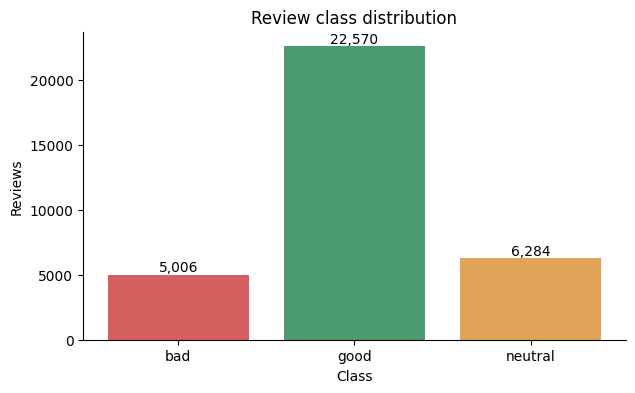

In [3]:
class_counts = (
    data['review_type']
    .value_counts()
    .with_columns((pl.col('count') / data.height).alias('share'))
    .sort('review_type')
)
display(class_counts)

counts_by_label = class_counts.to_dict(as_series=False)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts_by_label['review_type'], counts_by_label['count'], color=['#d65f5f', '#4c9a70', '#e0a458'])
ax.bar_label(bars, fmt='{:,.0f}')
ax.set(title='Review class distribution', xlabel='Class', ylabel='Reviews')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 4. Длина отзывов

Для BERT важно проверить длину текстов: при жёстком усечении теряется часть длинных рецензий. Здесь смотрим количество символов; для ноутбука с RuBERT дополнительно стоит измерить длину именно в токенах выбранного токенизатора.

Min / max characters: 71 / 10029
Quantiles: {'25%': 1488, '50%': 2145, '75%': 3136, '90%': 4401, '95%': 5323, '99%': 6721}


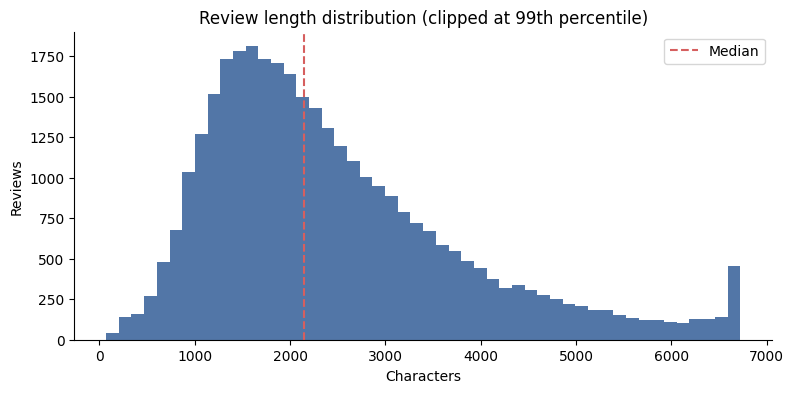

In [4]:
text_lengths = data.select(pl.col('user_review').str.len_chars().alias('characters'))['characters']
length_quantiles = {
    f'{int(q * 100)}%': int(text_lengths.quantile(q))
    for q in (0.25, 0.5, 0.75, 0.9, 0.95, 0.99)
}
print(f'Min / max characters: {text_lengths.min()} / {text_lengths.max()}')
print(f'Quantiles: {length_quantiles}')

upper_limit = text_lengths.quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(text_lengths.clip(upper_bound=upper_limit), bins=50, color='#5276a7')
ax.axvline(text_lengths.median(), color='#d65f5f', linestyle='--', label='Median')
ax.set(title='Review length distribution (clipped at 99th percentile)', xlabel='Characters', ylabel='Reviews')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 5. Воспроизводимое разбиение

Используем одинаковое стратифицированное разбиение для всех классических моделей. Тестовая выборка не участвует в обучении векторизатора или подборе параметров.

In [5]:
texts = data['user_review'].to_list()
labels = data['review_type'].to_list()

train_texts, test_texts, train_labels, test_labels = train_test_split(
    texts,
    labels,
    test_size=0.2,
    random_state=SEED,
    stratify=labels,
)
print(f'Train: {len(train_texts):,}; test: {len(test_texts):,}')

Train: 27,088; test: 6,772


## 6. Мажоритарный прогноз и TF-IDF baseline

Сначала измеряем модель, которая всегда выбирает самый частый класс. Затем обучаем логистическую регрессию на словах и биграммах. `class_weight='balanced'` повышает вклад редких классов в функцию потерь.

In [6]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(train_texts, train_labels)
dummy_predictions = dummy.predict(test_texts)

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.995,
        max_features=75_000,
        sublinear_tf=True,
        dtype=np.float32,
    )),
    ('classifier', LogisticRegression(
        C=2.0,
        class_weight='balanced',
        solver='liblinear',
        max_iter=1_000,
        random_state=SEED,
    )),
])
baseline.fit(train_texts, train_labels)
baseline_predictions = baseline.predict(test_texts)

results = []
for model_name, predictions in [('Majority class', dummy_predictions), ('TF-IDF + Logistic Regression', baseline_predictions)]:
    results.append({
        'model': model_name,
        'accuracy': accuracy_score(test_labels, predictions),
        'macro_f1': f1_score(test_labels, predictions, average='macro'),
        'weighted_f1': f1_score(test_labels, predictions, average='weighted'),
    })
pl.DataFrame(results).with_columns(pl.col(['accuracy', 'macro_f1', 'weighted_f1']).round(4))

model,accuracy,macro_f1,weighted_f1
str,f64,f64,f64
"""Majority class""",0.6666,0.2666,0.5332
"""TF-IDF + Logistic Regression""",0.7832,0.6541,0.7677


              precision    recall  f1-score   support

         bad      0.653     0.690     0.671      1001
        good      0.856     0.931     0.892      4514
     neutral      0.512     0.328     0.400      1257

    accuracy                          0.783      6772
   macro avg      0.674     0.650     0.654      6772
weighted avg      0.762     0.783     0.768      6772



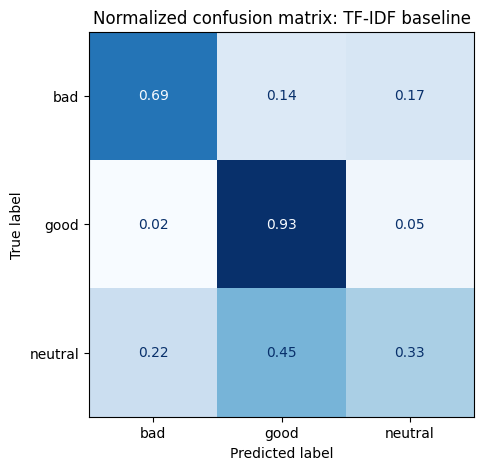

In [7]:
print(classification_report(test_labels, baseline_predictions, labels=LABELS, digits=3))

matrix = confusion_matrix(test_labels, baseline_predictions, labels=LABELS, normalize='true')
display_matrix = ConfusionMatrixDisplay(matrix, display_labels=LABELS)
fig, ax = plt.subplots(figsize=(6, 5))
display_matrix.plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
ax.set_title('Normalized confusion matrix: TF-IDF baseline')
plt.show()

## 7. Что выучила линейная модель

Наибольшие коэффициенты показывают слова и биграммы, которые сильнее всего сдвигают прогноз к каждому классу. Это не причинно-следственный анализ, но полезная проверка на артефакты данных.

In [8]:
feature_names = baseline.named_steps['tfidf'].get_feature_names_out()
classifier = baseline.named_steps['classifier']
for class_index, class_name in enumerate(classifier.classes_):
    top_indices = np.argsort(classifier.coef_[class_index])[-15:][::-1]
    top_features = ', '.join(feature_names[top_indices])
    print(f'{class_name}: {top_features}')

bad: видимо, ничего, вместо, ни, разочарование, зачем, нет, не понравился, откровенно, понимаю, увы, бред, неужели, попытка, якобы
good: 10 из, 10, каждый, не только, рекомендую, просмотру, именно, отлично, роль, идеально, из 10, атмосфера, очень, отличный, прекрасно
neutral: неплохой, но не, целом, однако, вот, местами, хотя, впечатление, большего, нейтральная, посмотреть можно, фильм, смотрела, не могу, фильм хороший


## 8. Примеры предсказаний

Несколько ручных примеров показывают формат inference, но не заменяют метрики на тестовой выборке.

In [9]:
def predict_review(text):
    probabilities = baseline.predict_proba([text])[0]
    prediction_index = probabilities.argmax()
    return {
        'label': str(baseline.classes_[prediction_index]),
        'confidence': float(probabilities[prediction_index]),
        'probabilities': {str(label): float(probability) for label, probability in zip(baseline.classes_, probabilities.round(4))},
    }

examples = [
    'Потрясающий фильм, отличная игра актёров и очень интересный сюжет!',
    'Ужасное кино: скучно, нелогично, актёры совершенно не убедительны.',
    'Средний фильм: есть как удачные сцены, так и заметные недостатки.',
]
for example in examples:
    print(example)
    print(predict_review(example), '\n')

Потрясающий фильм, отличная игра актёров и очень интересный сюжет!
{'label': 'good', 'confidence': 0.6748809207024608, 'probabilities': {'bad': 0.0297, 'good': 0.6749, 'neutral': 0.2954}} 

Ужасное кино: скучно, нелогично, актёры совершенно не убедительны.
{'label': 'neutral', 'confidence': 0.45566464547403324, 'probabilities': {'bad': 0.4301, 'good': 0.1142, 'neutral': 0.4557}} 

Средний фильм: есть как удачные сцены, так и заметные недостатки.
{'label': 'neutral', 'confidence': 0.7071195132045723, 'probabilities': {'bad': 0.0445, 'good': 0.2484, 'neutral': 0.7071}} 



## 9. Выводы

- После удаления трёх полных дубликатов осталось **33 860 отзывов**; пустых текстов и конфликтов меток нет.
- Мажоритарный прогноз даёт accuracy **0.667** и macro F1 **0.267**.
- TF-IDF с логистической регрессией достигает accuracy **0.783**, macro F1 **0.654** и weighted F1 **0.768**.
- Как и у первого RuBERT-эксперимента, основная сложность — `neutral`: F1 baseline для этого класса составляет **0.400**.
- Один из ручных примеров выше ошибочно отнесён к `neutral` вместо `bad`. Это наглядно показывает, почему вероятности и разбор ошибок важнее единственного красивого примера.

**Ограничения:** метки взяты из категорий отзывов источника, а не размечены вручную в этом проекте. В исходной версии отсутствуют названия фильмов, поэтому групповое разбиение по фильмам невозможно. Для строгого сравнения с RuBERT модели нужно оценить на одинаковом разбиении.